<a href="https://colab.research.google.com/github/s61711299-sketch/MSSP6070/blob/main/week12/PARTICIPATION_ACTIVITY_Week_12_Measure_a_p_value_from_a_t_test_on_a_data_set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
sns.set(style="ticks")

In [3]:
github_url = 'https://raw.githubusercontent.com/s61711299-sketch/MSSP6070/refs/heads/main/week12/Student%20Performance%20Data.csv'
df = pd.read_csv(github_url)

In [4]:
alpha = 0.05
completed = df[df['test preparation course'] == 'completed']['math score']
none = df[df['test preparation course'] == 'none']['math score']
t_stat, p_value = stats.ttest_ind(completed, none, equal_var=False)

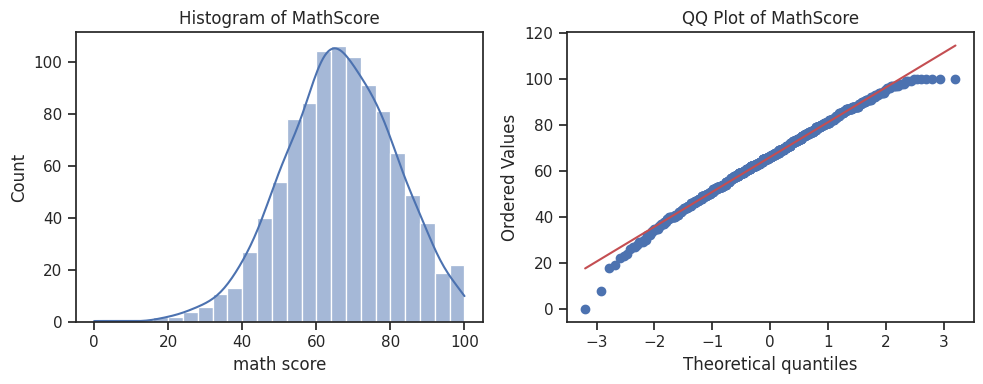

In [5]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['math score'], kde=True)
plt.title('Histogram of MathScore')
plt.subplot(1, 2, 2)
stats.probplot(df['math score'], dist="norm", plot=plt)
plt.title('QQ Plot of MathScore')
plt.tight_layout()
plt.show()

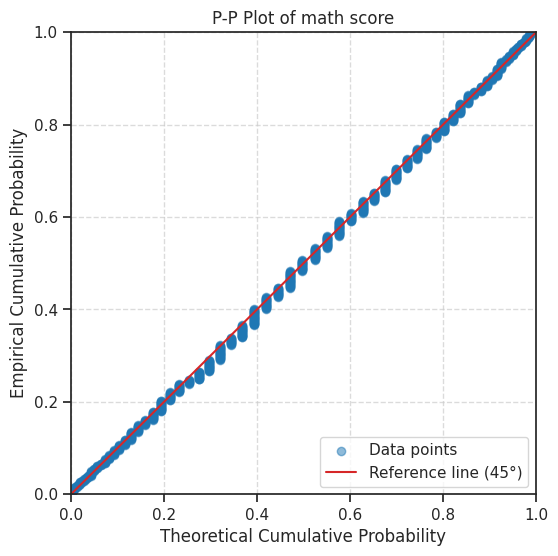

In [6]:
data = df['math score'].dropna()
sorted_data = np.sort(data)
n = len(sorted_data)
empirical_cdf = (np.arange(1, n + 1) - 0.5) / n
sample_mean = np.mean(sorted_data)
sample_sd = np.std(sorted_data, ddof=1)
theoretical_cdf = stats.norm.cdf(sorted_data, loc=sample_mean, scale=sample_sd)
plt.figure(figsize=(6, 6))
plt.scatter(theoretical_cdf, empirical_cdf, alpha=0.5, c='tab:blue', label='Data points')
plt.plot([0, 1], [0, 1], color='tab:red', linestyle='-', label='Reference line (45°)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel('Theoretical Cumulative Probability')
plt.ylabel('Empirical Cumulative Probability')
plt.title('P-P Plot of math score')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [9]:
alpha = 0.05
completed = df[df['test preparation course'] == 'completed']['math score'].dropna()
none = df[df['test preparation course'] == 'none']['math score'].dropna()
print(f"average score of students attending the course: {completed.mean():.2f}")
print(f"average score of students not attending the course: {none.mean():.2f}")
t_stat, p_value = stats.ttest_ind(completed, none, equal_var=False)
print("-" * 30)
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")
if p_value < alpha:
    print(f"Conclusion: Reject H0. (p-value {p_value:.4f} < {alpha})")
else:
    print(f"Conclusion: Fail to reject H0. (p-value {p_value:.4f} >= {alpha})")

average score of students attending the course: 69.70
average score of students not attending the course: 64.08
------------------------------
T-statistic: 5.7870
P-value: 0.000000
Conclusion: Reject H0. (p-value 0.0000 < 0.05)
结论：拒绝原假设。参加备考课程与未参加备考课程的学生数学成绩有显著差异。


/tmp/ipykernel_7922/409093009.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='test preparation course', y='math score', data=df, palette='Set2')


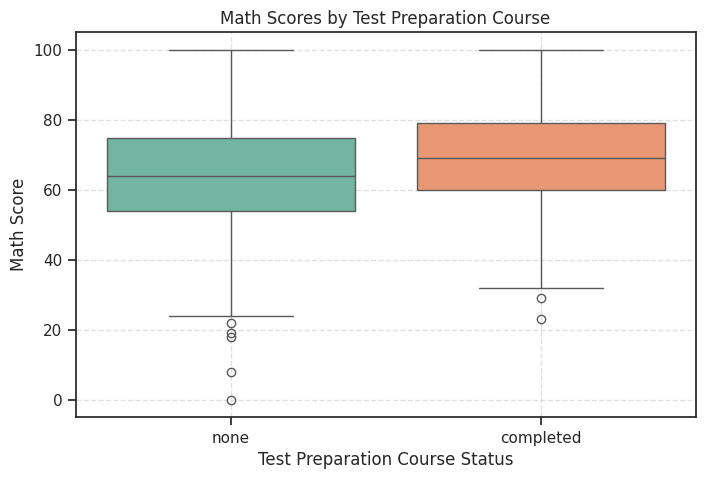

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='test preparation course', y='math score', data=df, palette='Set2')
plt.title('Math Scores by Test Preparation Course')
plt.xlabel('Test Preparation Course Status')
plt.ylabel('Math Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()